# House Prices - Exploratory Data Analysis

## 1. Introduction

The goal of this project is to predict house sale prices using machine learning.

This notebook explores the dataset, examines feature distributions, identifies missing values, analyzes numerical and categorical variables, and investigates potential relationships between property characteristics and the target variable `SalePrice`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

plt.style.use('dark_background')

plt.rcParams.update({
    'figure.figsize': (10, 6),
    'figure.dpi': 120,
    'font.size': 12,
    'axes.grid': True,
    'grid.alpha': 0.2,
})

In [2]:
DATA_DIR = Path('../data')

train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')

print('Train shape:', train.shape)
print('Test shape:', test.shape)

Train shape: (1460, 81)
Test shape: (1459, 80)


In [3]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [5]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
train.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


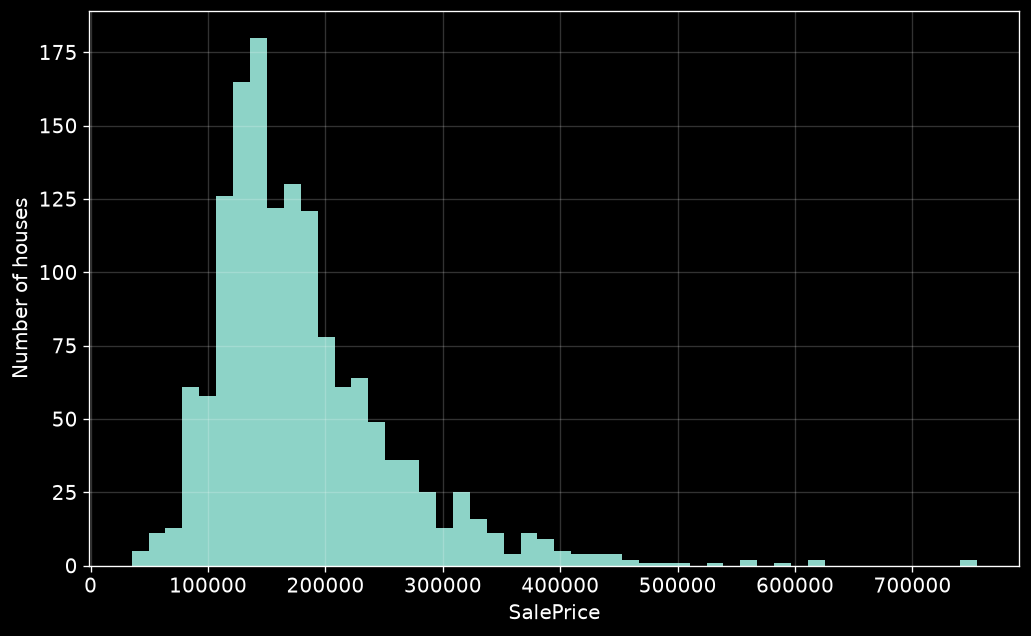

In [7]:
print(train['SalePrice'].describe())
train['SalePrice'].hist(bins=50)
plt.ylabel('Number of houses')
plt.xlabel('SalePrice')
plt.show()

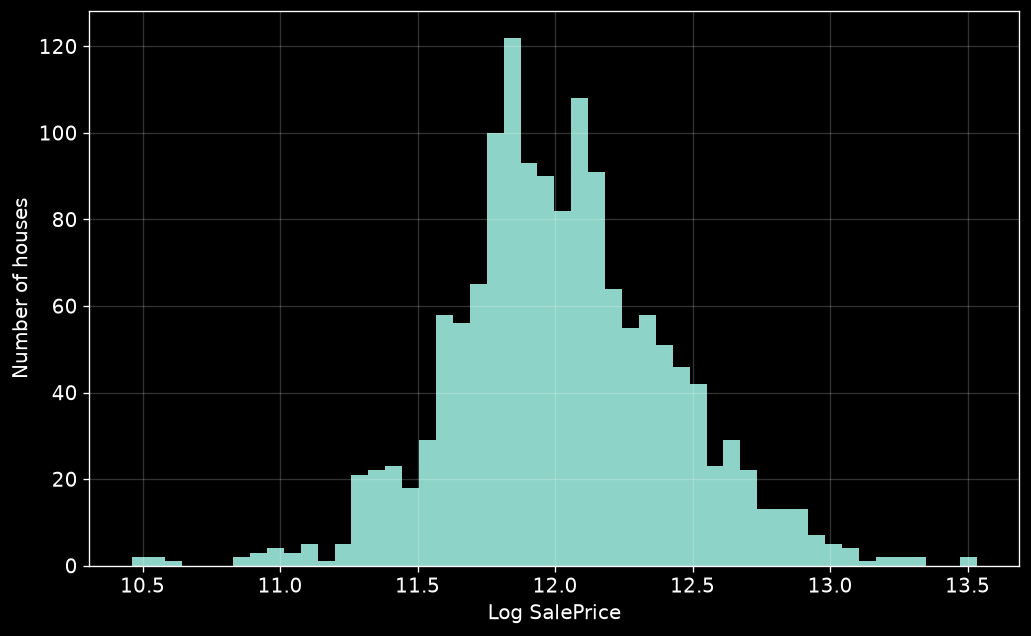

In [8]:
np.log(train['SalePrice']).hist(bins=50)
plt.ylabel('Number of houses')
plt.xlabel('Log SalePrice')
plt.show()

In [9]:
vars_with_na = [var for var in train.columns if train[var].isna().sum() > 0]

missing_ratio = train[vars_with_na].isnull().mean().sort_values(ascending=False)
missing_ratio.name=""
missing_ratio

PoolQC          0.995205
MiscFeature     0.963014
Alley           0.937671
Fence           0.807534
MasVnrType      0.597260
FireplaceQu     0.472603
LotFrontage     0.177397
GarageType      0.055479
GarageYrBlt     0.055479
GarageFinish    0.055479
GarageQual      0.055479
GarageCond      0.055479
BsmtExposure    0.026027
BsmtFinType2    0.026027
BsmtQual        0.025342
BsmtCond        0.025342
BsmtFinType1    0.025342
MasVnrArea      0.005479
Electrical      0.000685
Name: , dtype: float64

In [ ]:
missing_info = pd.DataFrame({
    'missing_count': train.isna().sum(),
    'missing_ratio': train.isna().mean(),
})

missing_info = missing_info[missing_info['missing_count'] > 0].sort_values(
    'missing_ratio',
    ascending=False
)

missing_info

,missing_count,missing_ratio
PoolQC,1453,0.995205
MiscFeature,1406,0.963014
Alley,1369,0.937671
Fence,1179,0.807534
MasVnrType,872,0.597260
FireplaceQu,690,0.472603
LotFrontage,259,0.177397
GarageType,81,0.055479
GarageYrBlt,81,0.055479
GarageFinish,81,0.055479


In [27]:
missing_semantics = {
    "PoolQC": "No pool",
    "MiscFeature": "No misc feature",
    "Alley": "No alley access",
    "Fence": "No fence",
    "FireplaceQu": "No fireplace",
    "GarageType": "No garage",
    "GarageYrBlt": "No garage",
    "GarageFinish": "No garage",
    "GarageQual": "No garage",
    "GarageCond": "No garage",
    "BsmtQual": "No basement",
    "BsmtCond": "No basement",
    "BsmtExposure": "No basement",
    "BsmtFinType1": "No basement",
    "BsmtFinType2": "No basement",
    "LotFrontage": "True missing",
    "Electrical": "True missing",
}

# MasVnrType MasVnrArea

for col in missing_info.index:
    print(
        col,
        missing_info.loc[col, "missing_ratio"],
        missing_semantics.get(col, "Needs investigation")
    )

PoolQC 0.9952054794520548 No pool
MiscFeature 0.963013698630137 No misc feature
Alley 0.9376712328767123 No alley access
Fence 0.8075342465753425 No fence
MasVnrType 0.5972602739726027 Needs investigation
FireplaceQu 0.4726027397260274 No fireplace
LotFrontage 0.1773972602739726 True missing
GarageType 0.05547945205479452 No garage
GarageYrBlt 0.05547945205479452 No garage
GarageFinish 0.05547945205479452 No garage
GarageQual 0.05547945205479452 No garage
GarageCond 0.05547945205479452 No garage
BsmtExposure 0.026027397260273973 No basement
BsmtFinType2 0.026027397260273973 No basement
BsmtQual 0.025342465753424658 No basement
BsmtCond 0.025342465753424658 No basement
BsmtFinType1 0.025342465753424658 No basement
MasVnrArea 0.005479452054794521 Needs investigation
Electrical 0.0006849315068493151 True missing


In [28]:
garage_cols = [
    "GarageType",
    "GarageYrBlt",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
]

train[garage_cols].isna().sum()

GarageType      81
GarageYrBlt     81
GarageFinish    81
GarageQual      81
GarageCond      81
dtype: int64

In [29]:
basement_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
]

train[basement_cols].isna().sum()

BsmtQual        37
BsmtCond        37
BsmtExposure    38
BsmtFinType1    37
BsmtFinType2    38
dtype: int64

- `SalePrice` is strongly right-skewed.
- A logarithmic transformation makes the target distribution considerably more symmetric.
- Missing values are highly feature-dependent and should not be handled uniformly.
- For several categorical features, missing values likely indicate the absence of a property component rather than unknown data.

In [10]:
feature_summary = pd.DataFrame({
    'dtype': train.dtypes,
    'missing_counts': train.isna().sum(),
    'missing_ratio': train.isna().mean(),
    'n_unique': train.nunique(),
})

feature_summary = feature_summary.sort_values(
    'missing_ratio',
    ascending=False,
)

feature_summary

,dtype,missing_counts,missing_ratio,n_unique
PoolQC,str,1453,0.995205,3
MiscFeature,str,1406,0.963014,4
Alley,str,1369,0.937671,2
Fence,str,1179,0.807534,4
MasVnrType,str,872,0.597260,3
...,...,...,...,...
MoSold,int64,0,0.000000,12
YrSold,int64,0,0.000000,5
SaleType,str,0,0.000000,9
SaleCondition,str,0,0.000000,6


In [11]:
target = 'SalePrice'

numerical_features = train.select_dtypes(
    include=['int64', 'float64']
).columns.drop(target)

categorical_features = train.select_dtypes(
    include=['object', 'string']
).columns

print(f'numerical: {len(numerical_features)}')
print(f'categorical: {len(categorical_features)}')

numerical: 37
categorical: 43


In [12]:
train['MasVnrType'].value_counts(dropna=False)

MasVnrType
NaN        872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

In [13]:
mumerical_cols = train.select_dtypes(
    include=['int64', 'float64'],
).columns

corr_with_target = (
    train[mumerical_cols]
    .corr()['SalePrice']
    .sort_values(ascending=False),
)

corr_with_target

(SalePrice        1.000000
 OverallQual      0.790982
 GrLivArea        0.708624
 GarageCars       0.640409
 GarageArea       0.623431
 TotalBsmtSF      0.613581
 1stFlrSF         0.605852
 FullBath         0.560664
 TotRmsAbvGrd     0.533723
 YearBuilt        0.522897
 YearRemodAdd     0.507101
 GarageYrBlt      0.486362
 MasVnrArea       0.477493
 Fireplaces       0.466929
 BsmtFinSF1       0.386420
 LotFrontage      0.351799
 WoodDeckSF       0.324413
 2ndFlrSF         0.319334
 OpenPorchSF      0.315856
 HalfBath         0.284108
 LotArea          0.263843
 BsmtFullBath     0.227122
 BsmtUnfSF        0.214479
 BedroomAbvGr     0.168213
 ScreenPorch      0.111447
 PoolArea         0.092404
 MoSold           0.046432
 3SsnPorch        0.044584
 BsmtFinSF2      -0.011378
 BsmtHalfBath    -0.016844
 MiscVal         -0.021190
 Id              -0.021917
 LowQualFinSF    -0.025606
 YrSold          -0.028923
 OverallCond     -0.077856
 MSSubClass      -0.084284
 EnclosedPorch   -0.128578
 

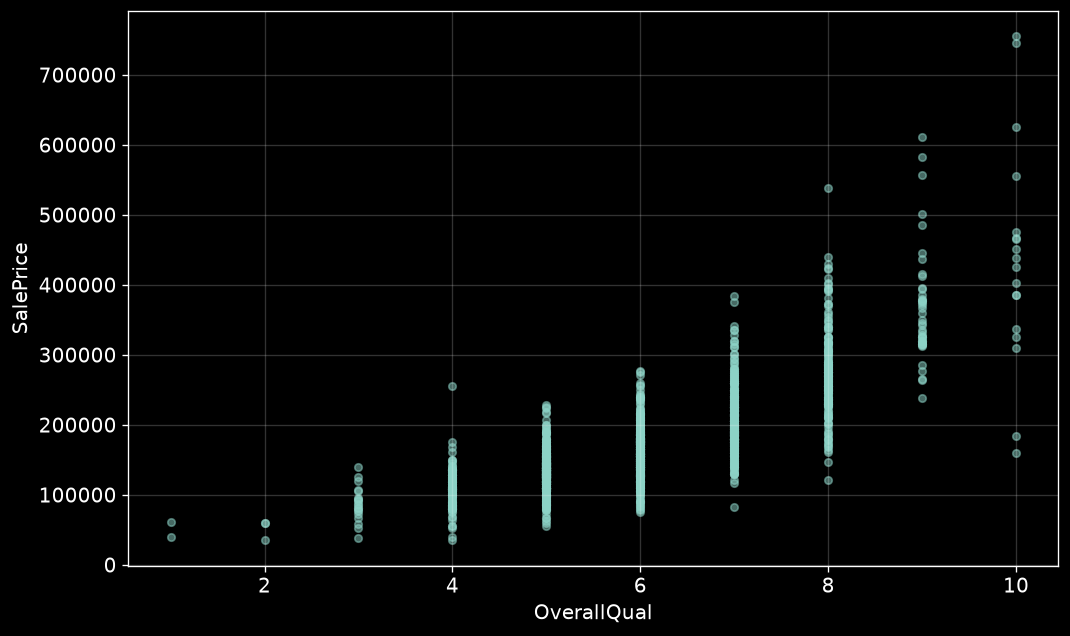

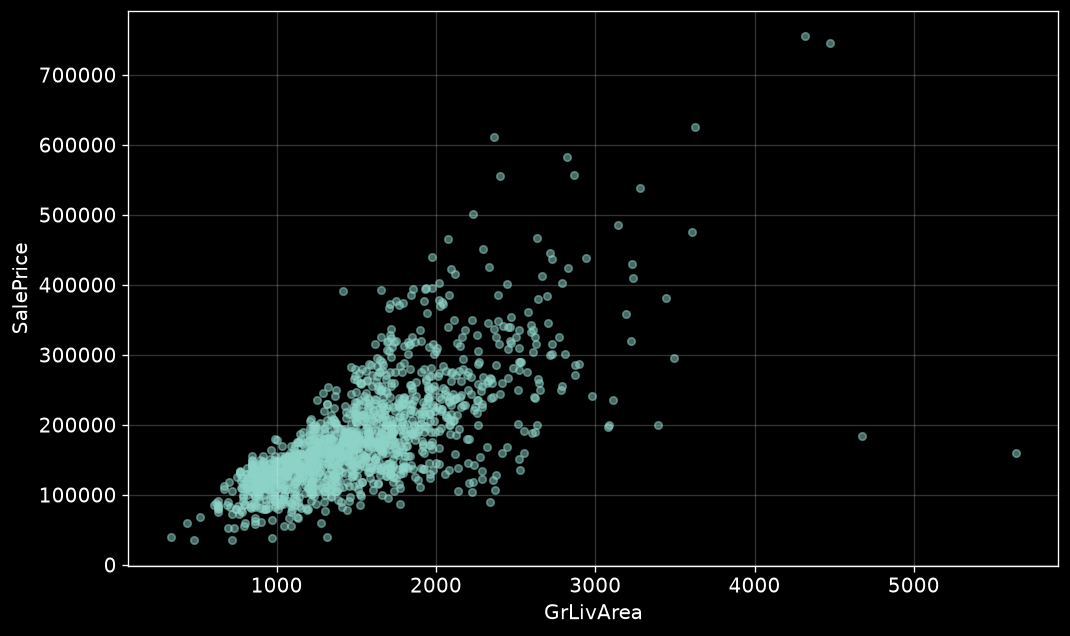

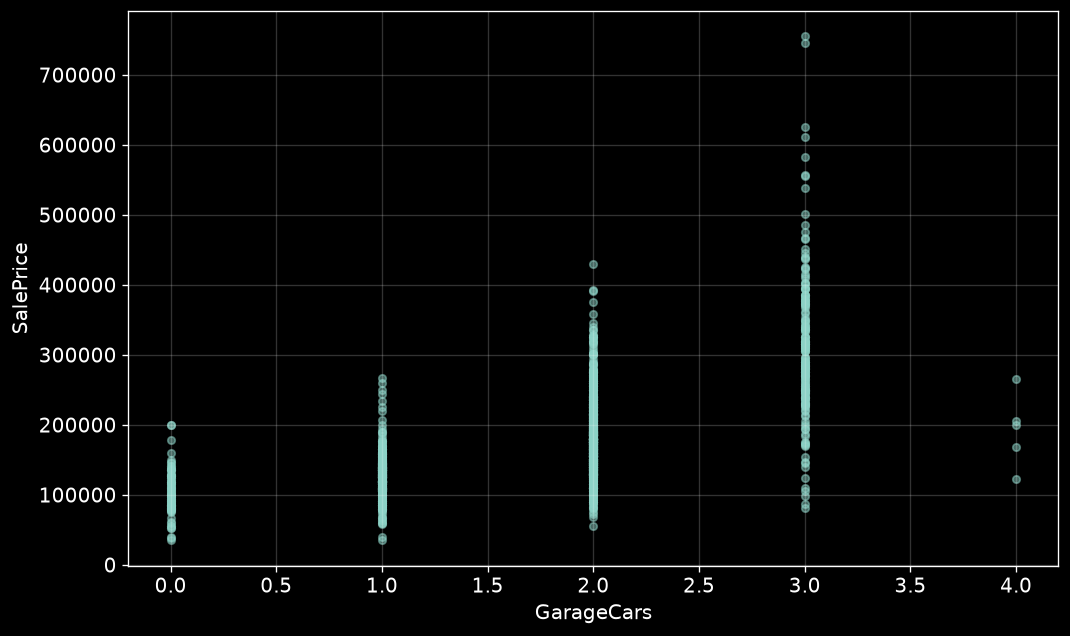

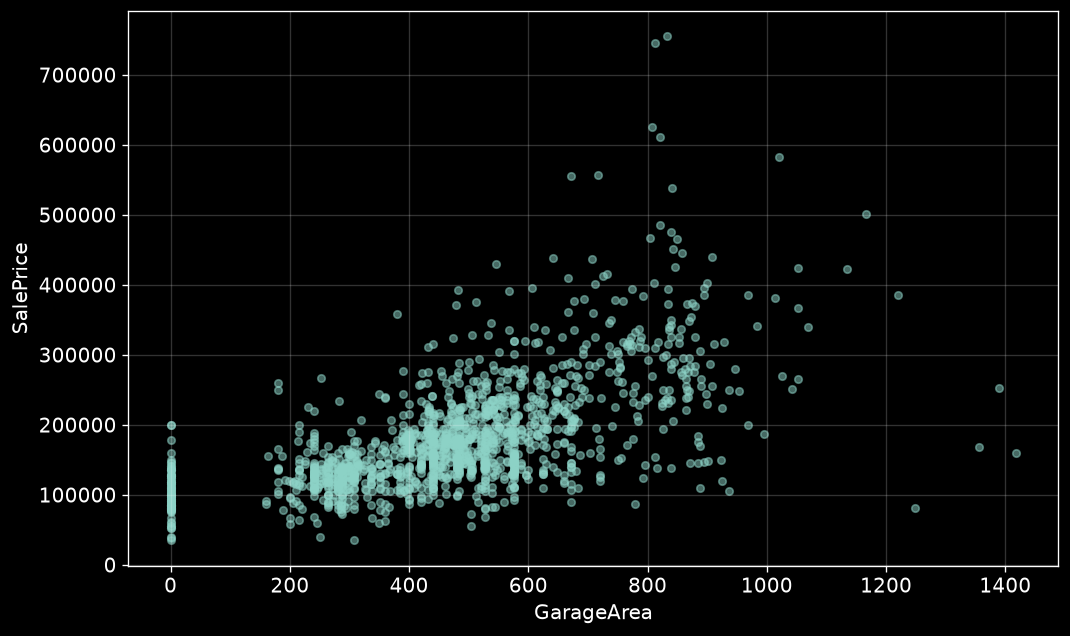

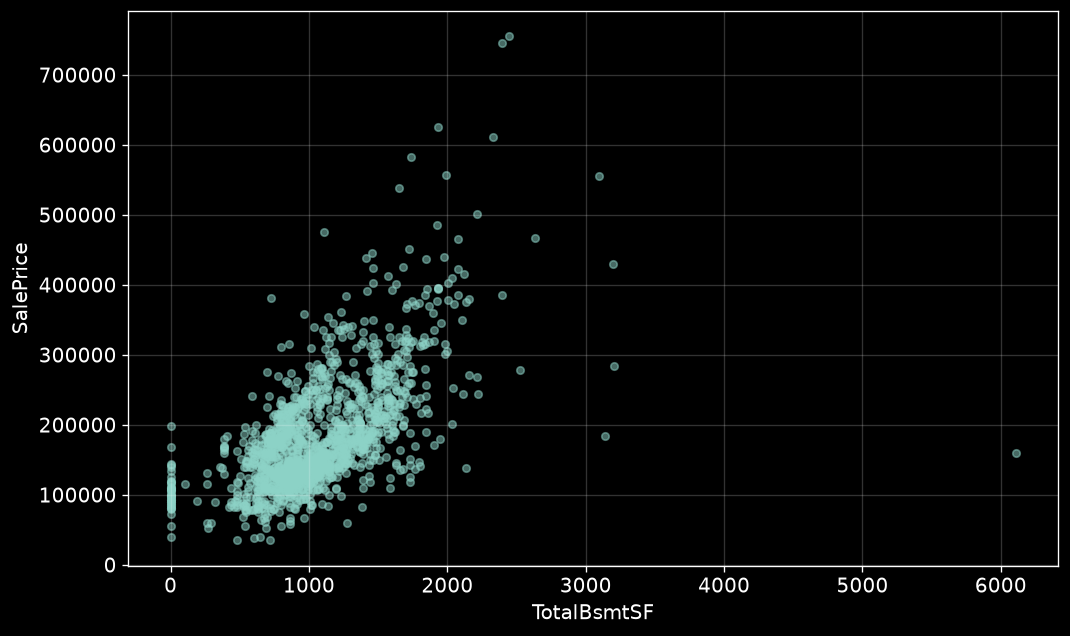

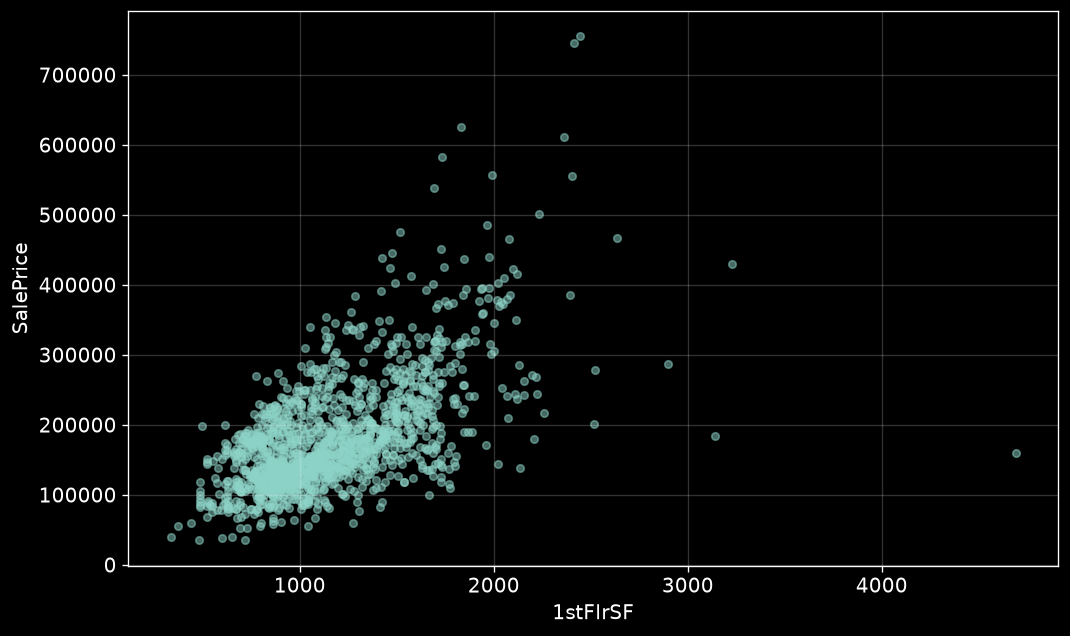

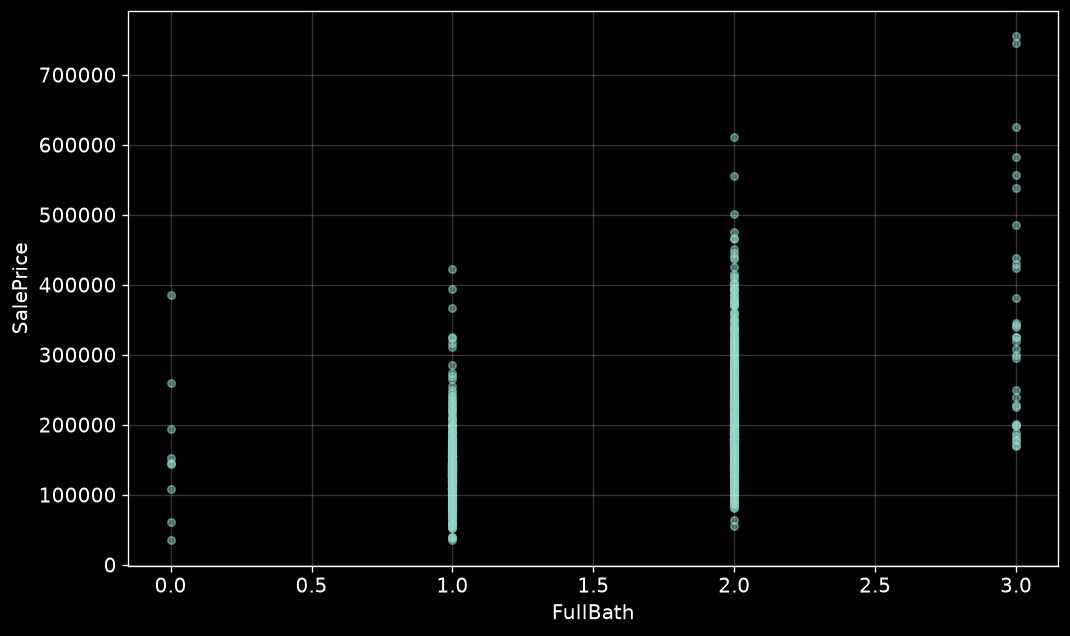

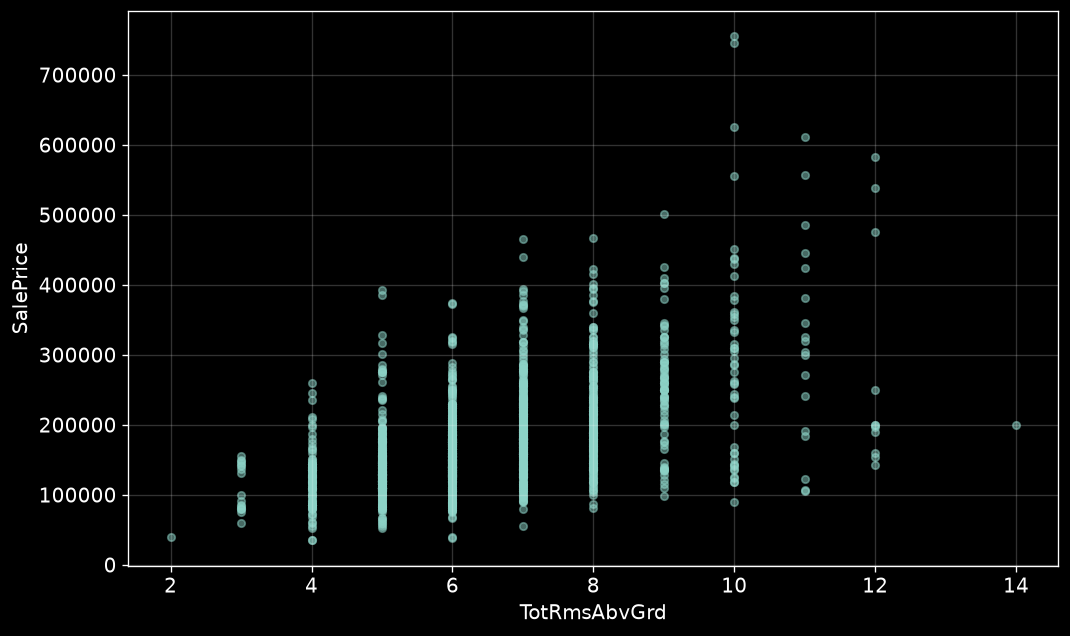

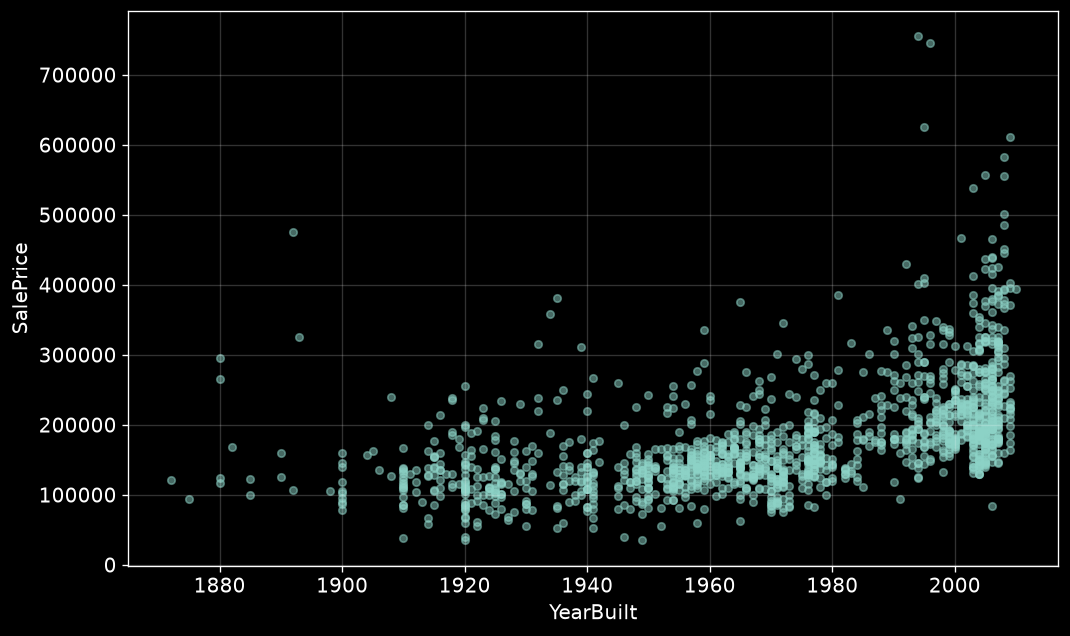

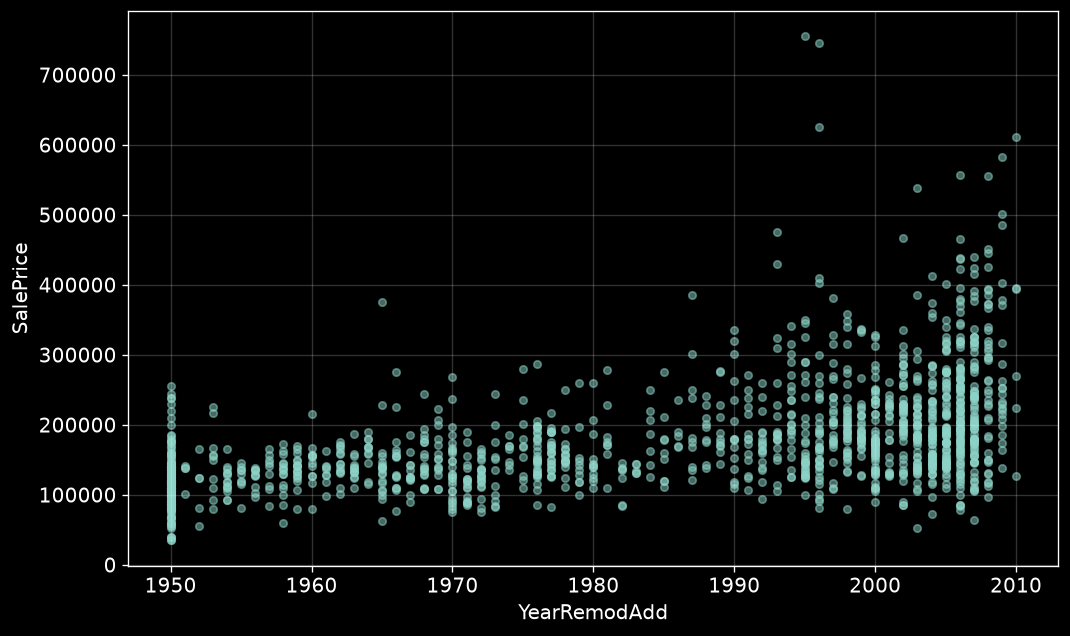

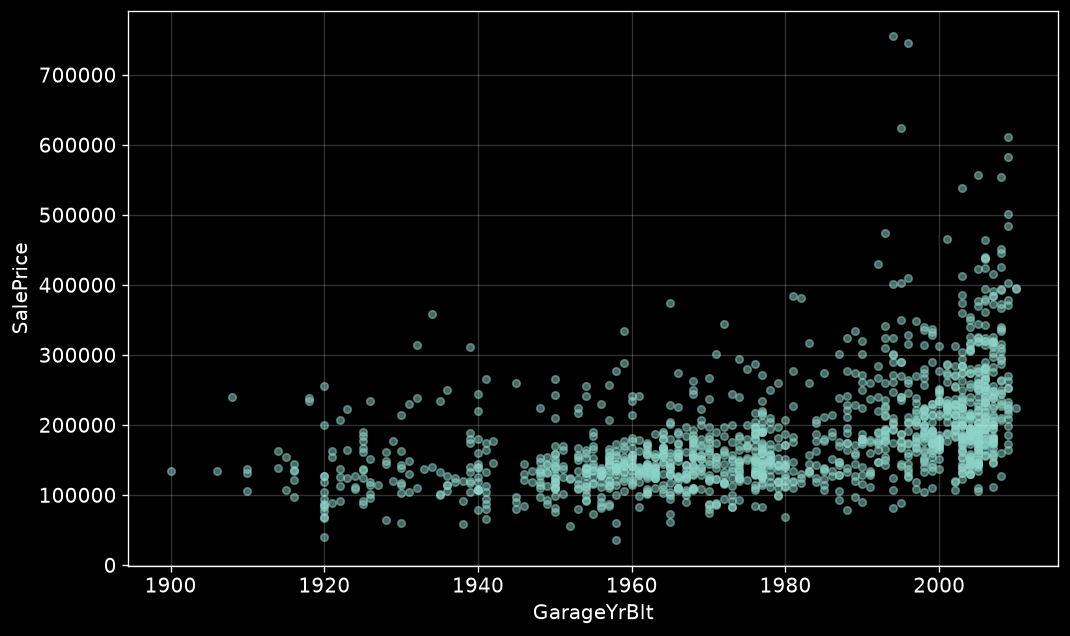

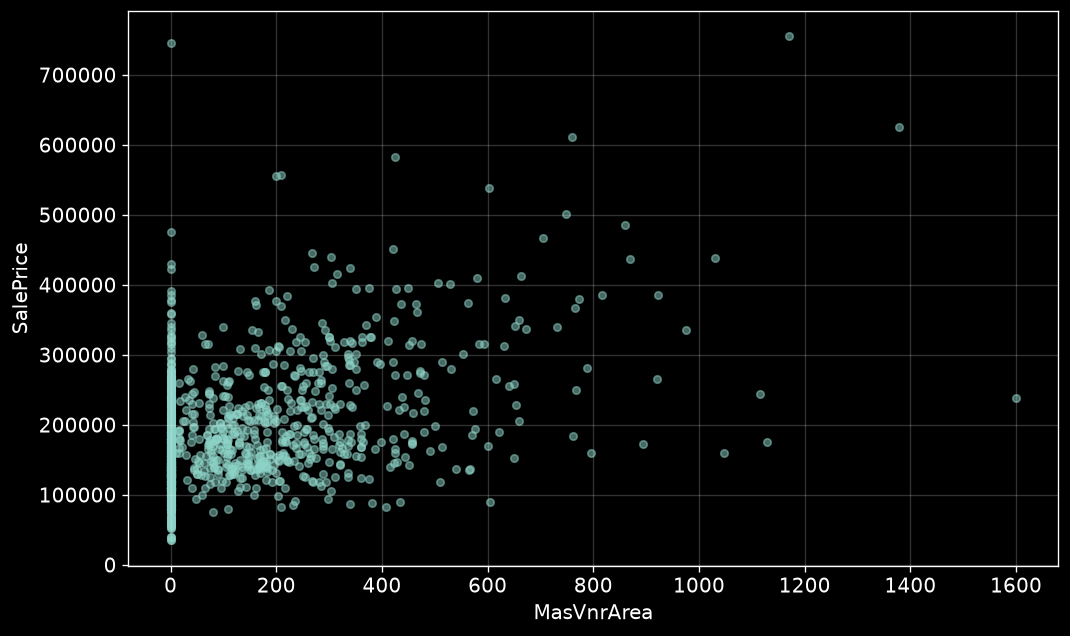

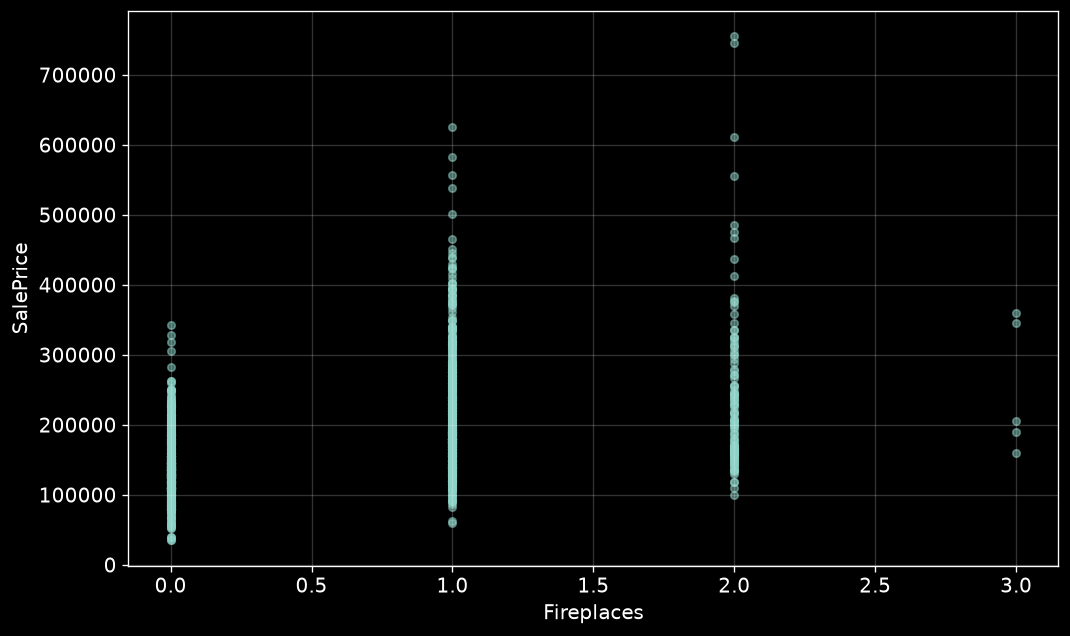

In [15]:
important_num = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'GarageArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'FullBath',
    'TotRmsAbvGrd',
    'YearBuilt',
    'YearRemodAdd',
    'GarageYrBlt',
    'MasVnrArea',
    'Fireplaces',
]

for col in important_num:
    train.plot.scatter(
        x=col,
        y='SalePrice',
        alpha=0.5,
    )
    plt.show()

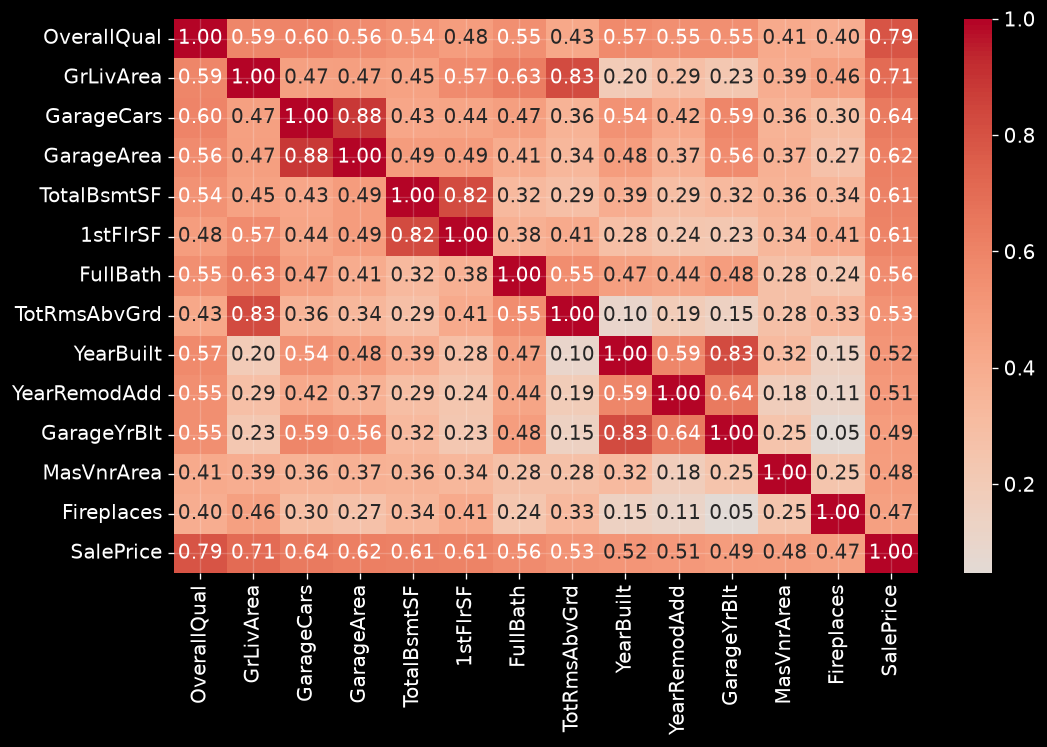

In [16]:
important_corr = train[
    important_num + ['SalePrice']
].corr()

sns.heatmap(
    important_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.show()

### Numerical Feature Correlations

Several numerical features show strong relationships with `SalePrice`.

The strongest correlations are observed for:

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`

Several feature pairs are also strongly correlated with each other, indicating partially redundant information:

- `GarageCars` and `GarageArea`
- `GrLivArea` and `TotRmsAbvGrd`
- `TotalBsmtSF` and `1stFlrSF`
- `YearBuilt` and `GarageYrBlt`

These features will be retained for now, since correlation alone does not imply that one should be removed. Their usefulness will be evaluated during modeling.

In [19]:
categorical_cols = train.select_dtypes(
    include=['object', 'string'],
).columns

cat_summary = pd.DataFrame({
    "n_unique": train[categorical_features].nunique(),
    "missing_ratio": train[categorical_features].isna().mean(),
})

cat_summary.sort_values(
    "n_unique",
    ascending=False,
)

,n_unique,missing_ratio
Neighborhood,25,0.000000
Exterior2nd,16,0.000000
Exterior1st,15,0.000000
Condition1,9,0.000000
SaleType,9,0.000000
HouseStyle,8,0.000000
RoofMatl,8,0.000000
Condition2,8,0.000000
Functional,7,0.000000
BsmtFinType2,6,0.026027


In [20]:
for col in categorical_features:
    stats = (
        train
        .groupby(col, dropna=False)['SalePrice']
        .agg(['count', 'median', 'mean'])
        .sort_values('median')
    )
    
    print(f"\n{col}")
    print(stats)


MSZoning
          count    median           mean
MSZoning                                
C (all)      10   74700.0   74528.000000
RM          218  120500.0  126316.830275
RH           16  136500.0  131558.375000
RL         1151  174000.0  191004.994787
FV           65  205950.0  214014.061538

Street
        count    median           mean
Street                                
Grvl        6  114250.0  130190.500000
Pave     1454  163000.0  181130.538514

Alley
       count    median           mean
Alley                                
Grvl      50  119500.0  122219.080000
NaN     1369  165000.0  183452.131483
Pave      41  172500.0  168000.585366

LotShape
          count    median           mean
LotShape                                
Reg         925  146000.0  164754.818378
IR1         484  189000.0  206101.665289
IR3          10  203570.0  216036.500000
IR2          41  221000.0  239833.365854

LandContour
             count    median           mean
LandContour                  

In [21]:
cat_target_summary = []

for col in categorical_features:
    stats = (
        train
        .groupby(col, dropna=False)['SalePrice']
        .agg(['count', 'median'])
    )
    
    cat_target_summary.append({
        'feature': col,
        'n_categories': len(stats),
        'min_median': stats['median'].min(),
        'max_median': stats['median'].max(),
        'median_range': (
            stats['median'].max() - stats['median'].min()
        )
    })
    
cat_target_summary = pd.DataFrame(cat_target_summary).sort_values(
    'median_range',
    ascending=False
)

cat_target_summary

,feature,n_categories,min_median,max_median,median_range
38,PoolQC,4,162900.0,490000.0,327100.0
18,ExterQual,4,82250.0,364606.5,282356.5
10,Condition2,8,96750.0,325000.0,228250.0
8,Neighborhood,25,88000.0,315000.0,227000.0
21,BsmtQual,5,101800.0,318000.0,216200.0
16,Exterior2nd,16,105000.0,319000.0,214000.0
30,KitchenQual,4,115000.0,316750.0,201750.0
14,RoofMatl,8,137000.0,332500.0,195500.0
15,Exterior1st,15,71000.0,262000.0,191000.0
32,FireplaceQu,6,131500.0,314250.0,182750.0


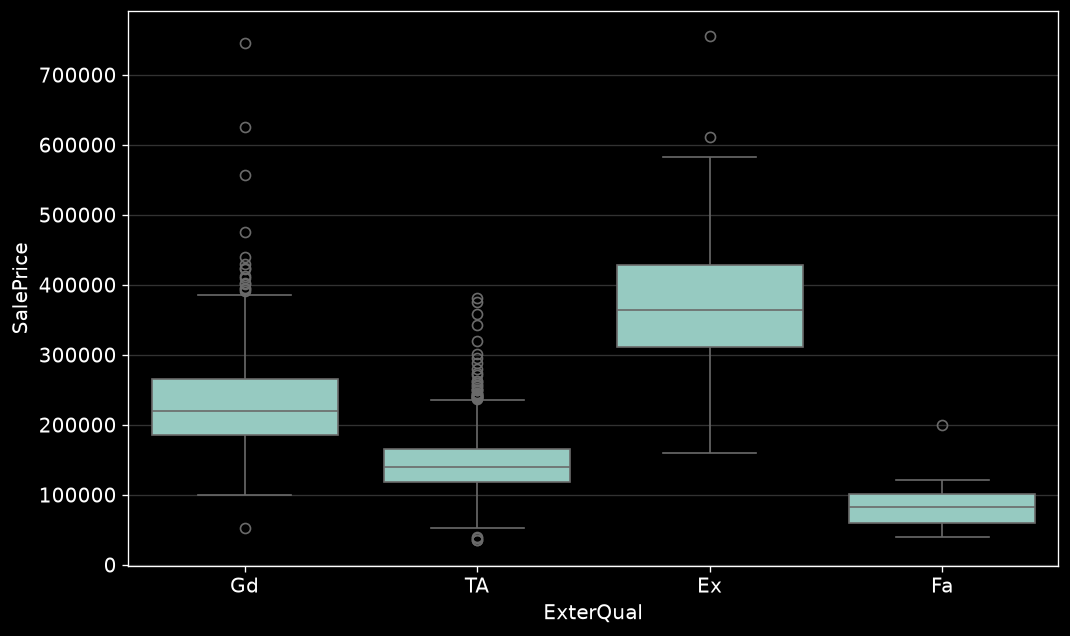

In [22]:
sns.boxplot(
    data=train,
    x="ExterQual",
    y="SalePrice",
)

plt.show()

In [23]:
cat_target_summary.head(10)

,feature,n_categories,min_median,max_median,median_range
38,PoolQC,4,162900.0,490000.0,327100.0
18,ExterQual,4,82250.0,364606.5,282356.5
10,Condition2,8,96750.0,325000.0,228250.0
8,Neighborhood,25,88000.0,315000.0,227000.0
21,BsmtQual,5,101800.0,318000.0,216200.0
16,Exterior2nd,16,105000.0,319000.0,214000.0
30,KitchenQual,4,115000.0,316750.0,201750.0
14,RoofMatl,8,137000.0,332500.0,195500.0
15,Exterior1st,15,71000.0,262000.0,191000.0
32,FireplaceQu,6,131500.0,314250.0,182750.0


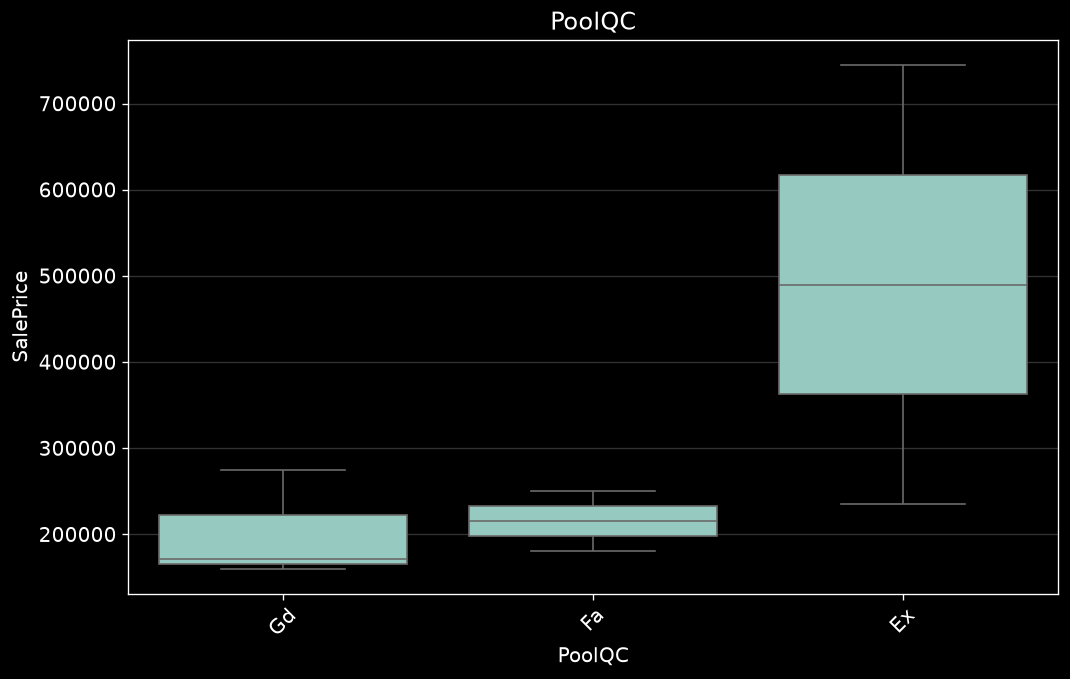

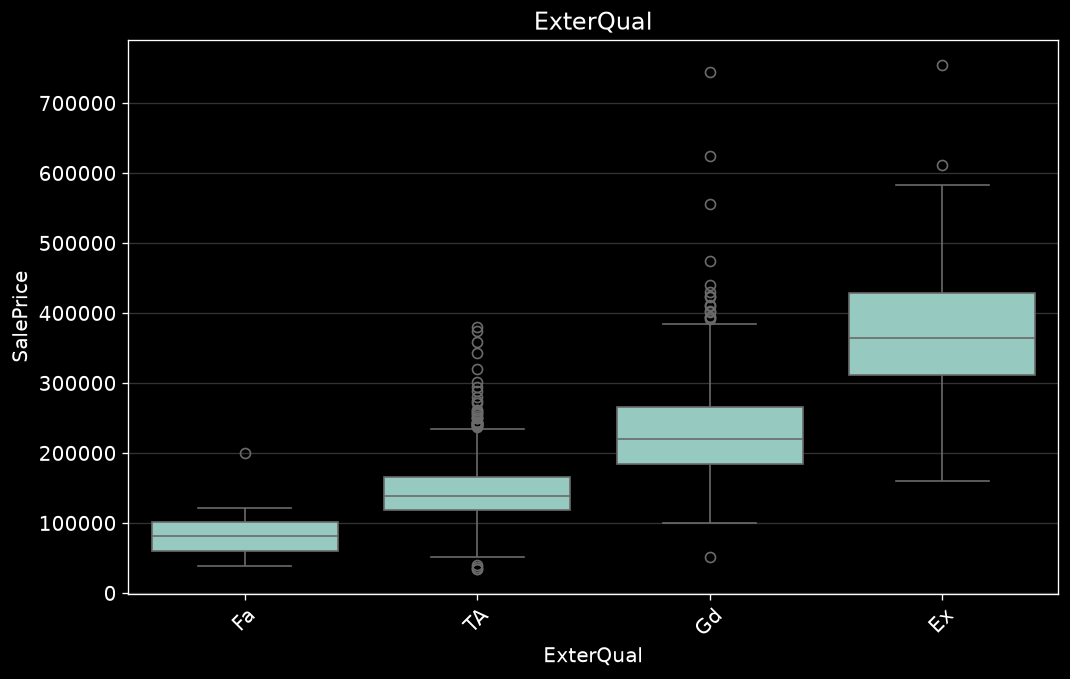

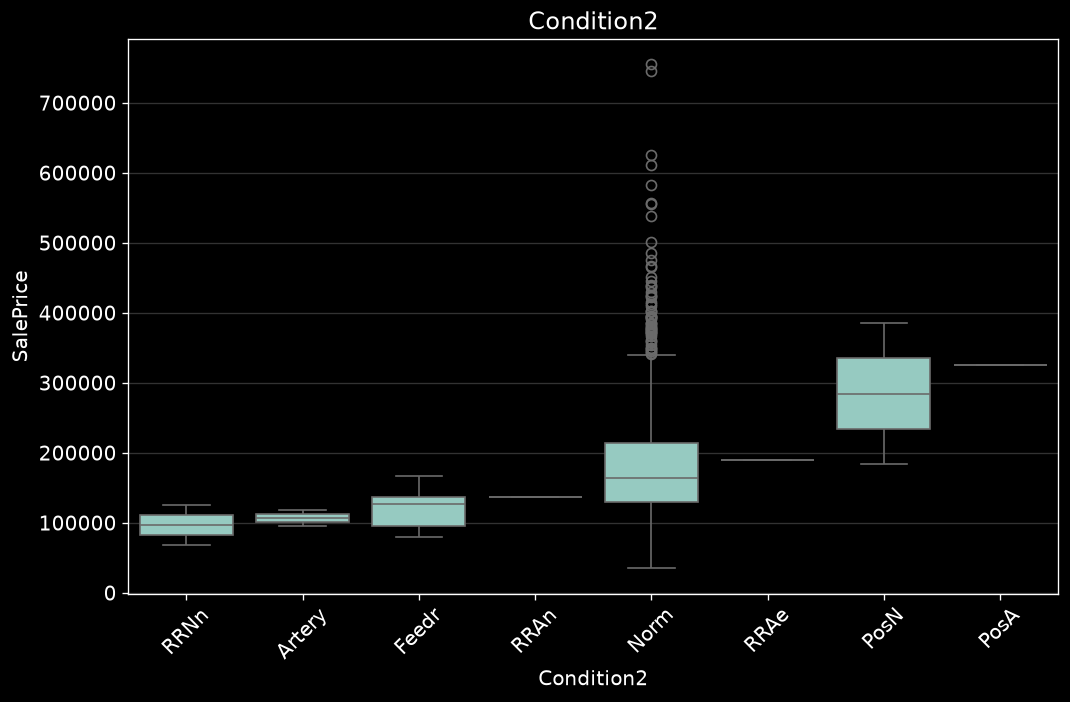

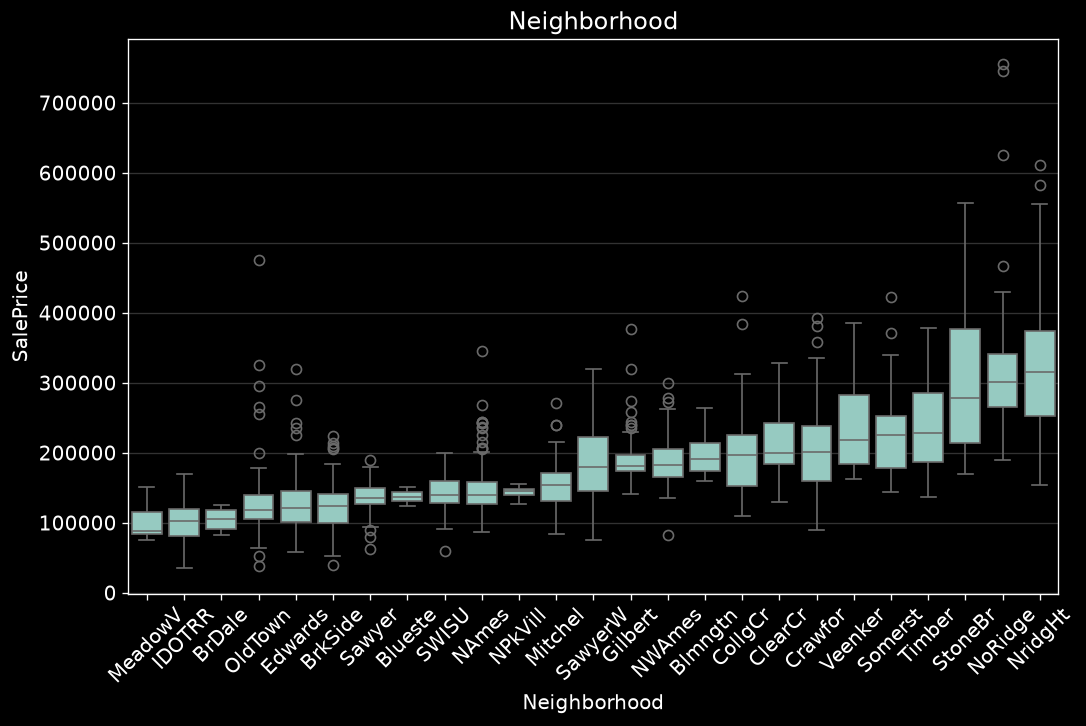

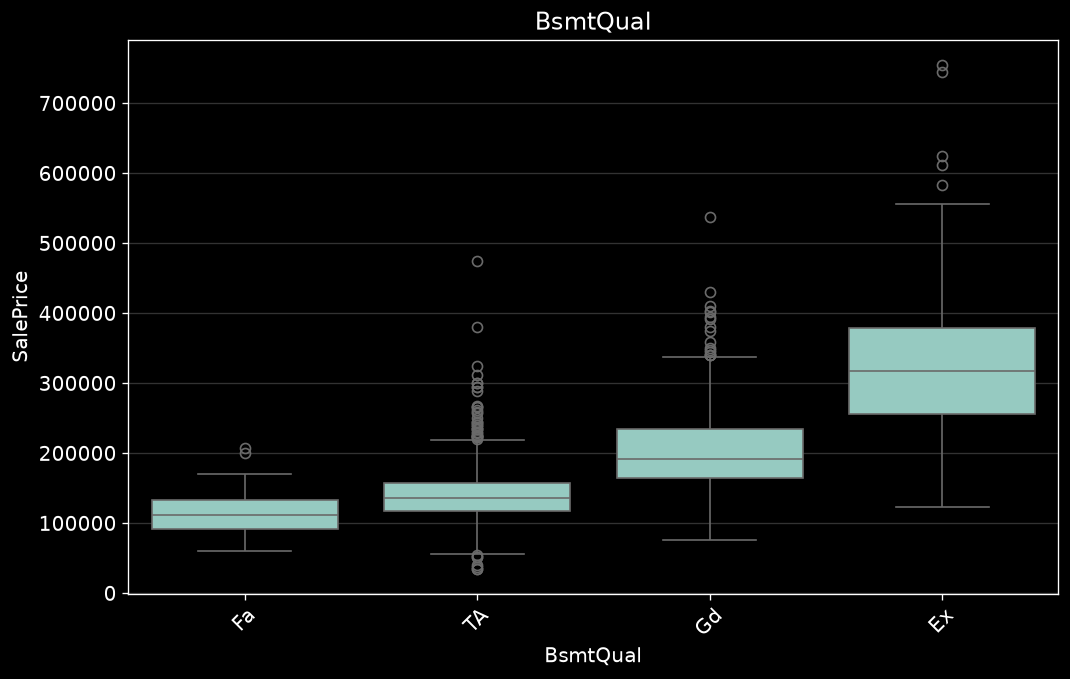

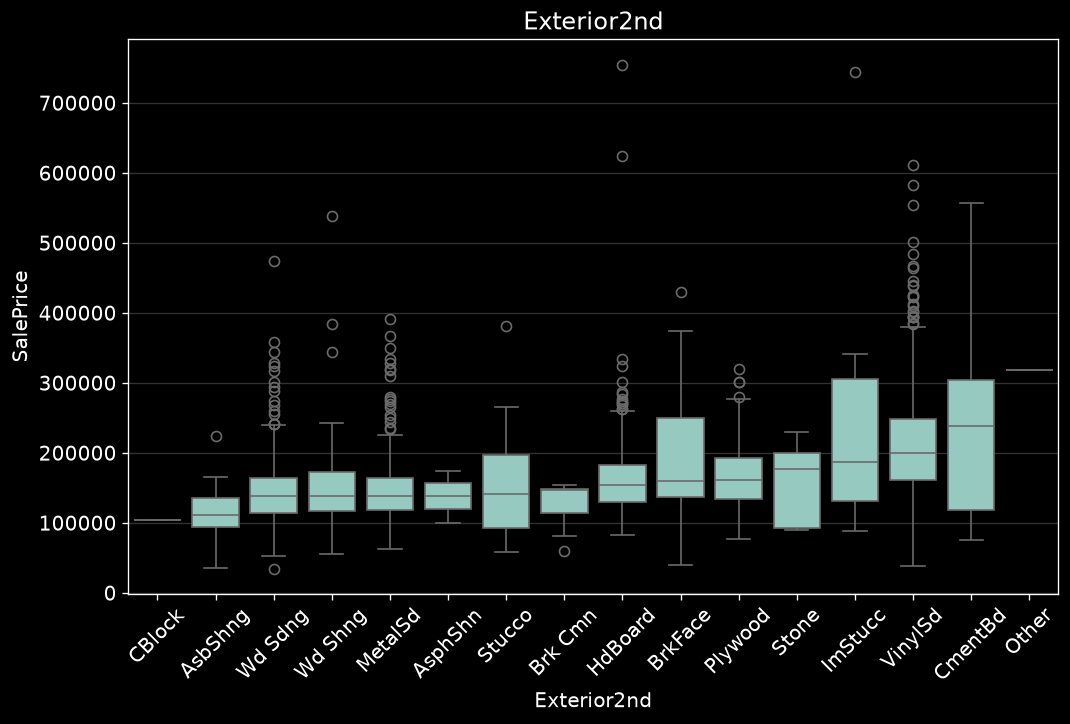

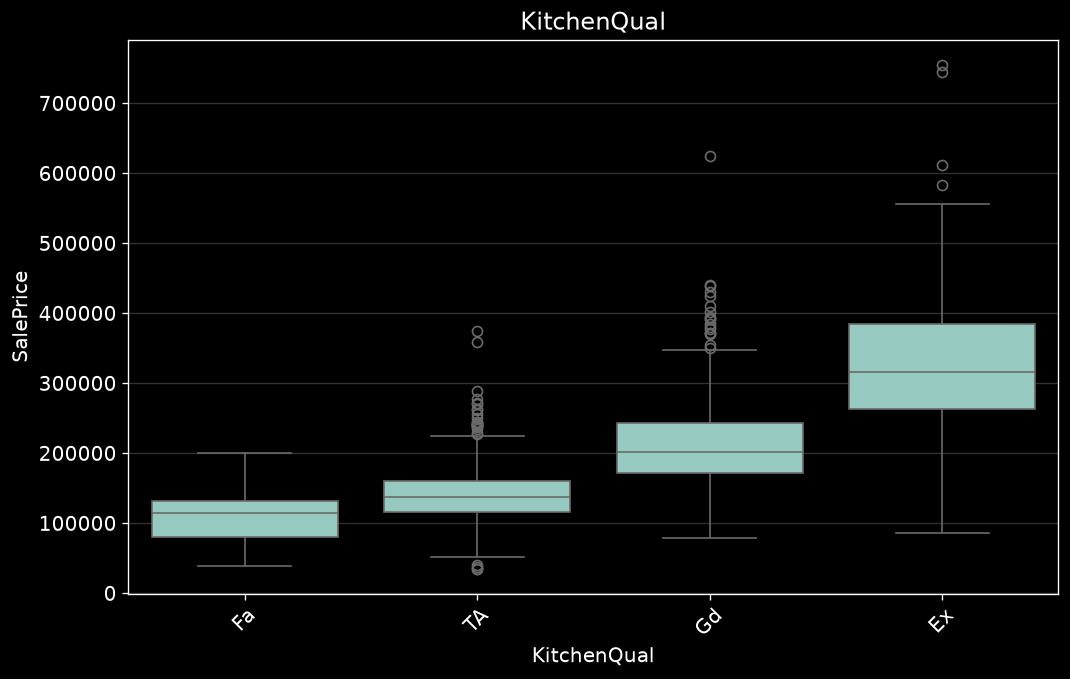

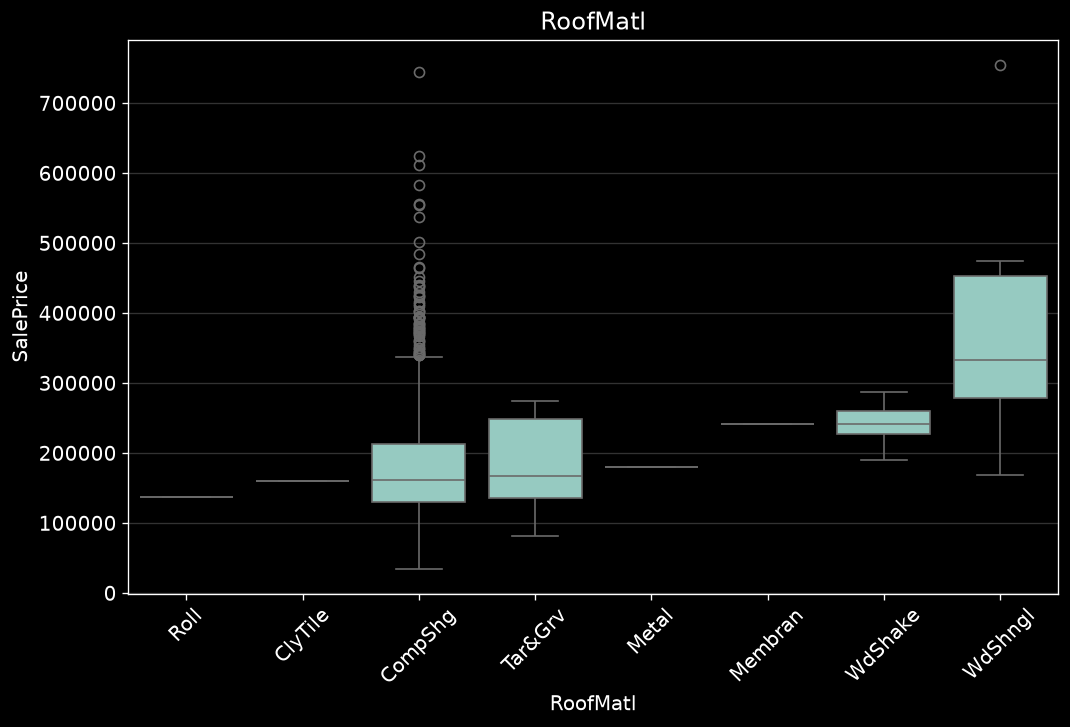

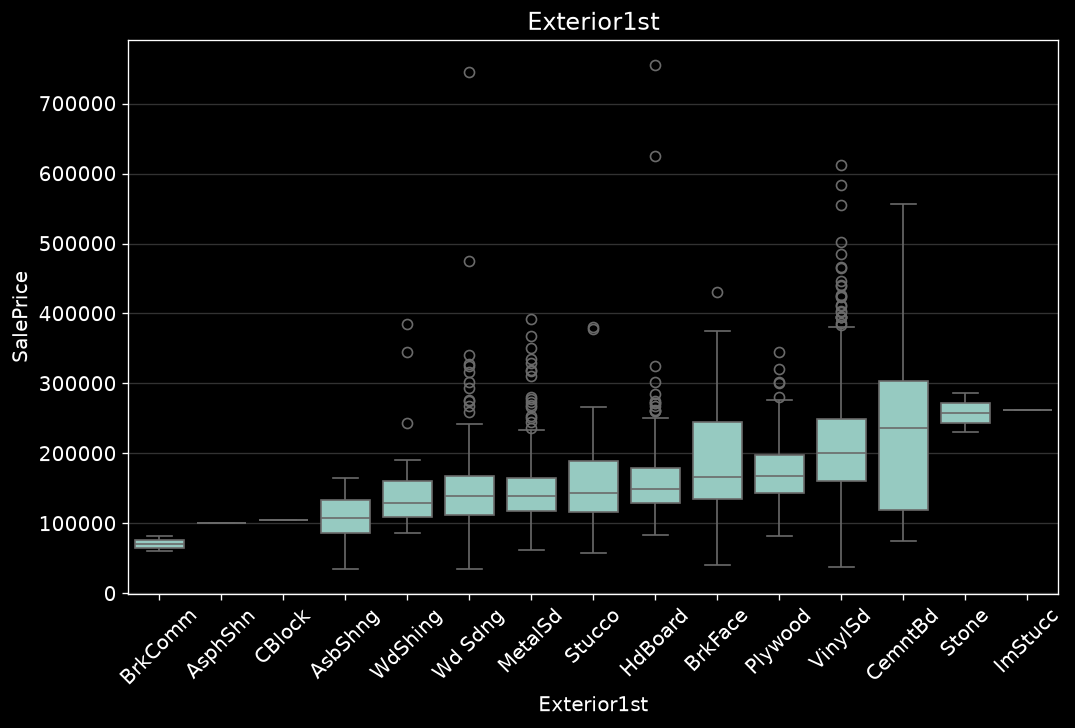

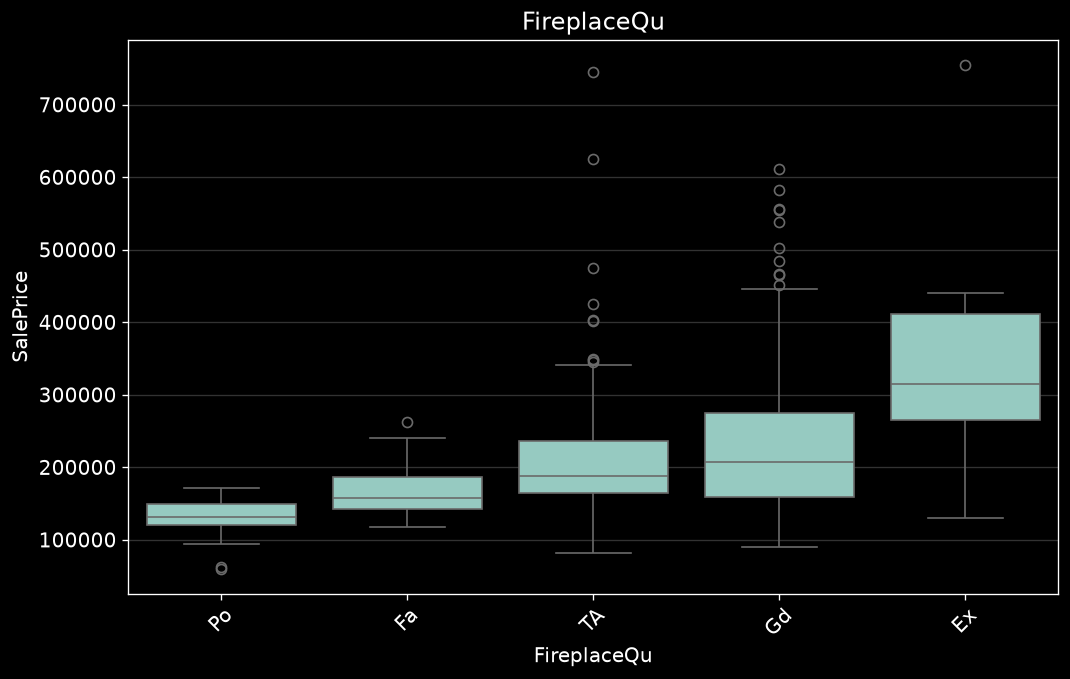

In [24]:
top_cat = cat_target_summary.head(10)['feature']

for col in top_cat:
    order = (
        train.groupby(col)['SalePrice']
        .median()
        .sort_values()
        .index
    )
    
    sns.boxplot(
        data=train,
        x=col,
        y='SalePrice',
        order=order
    )
    
    plt.xticks(rotation=45)
    plt.title(col)
    plt.show()

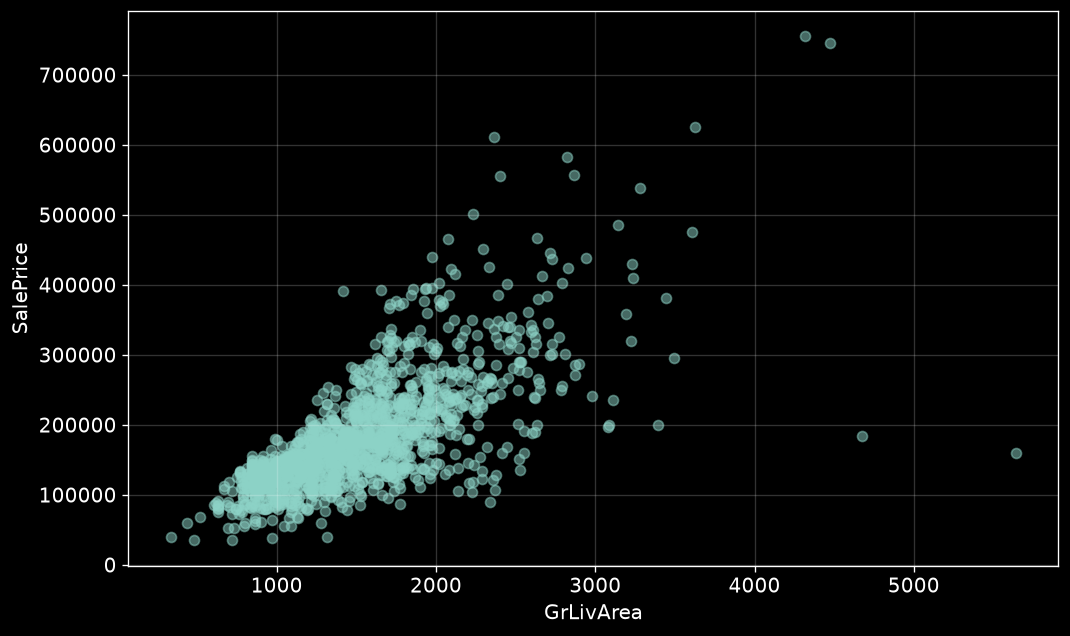

In [25]:
outlier_features = [
    "GrLivArea",
    "LotArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "GarageArea",
]

plt.scatter(
    train["GrLivArea"],
    train["SalePrice"],
    alpha=0.5,
)

plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.show()

## EDA Summary

The dataset contains a mixture of continuous, discrete, ordinal, categorical, and temporal features.

Key findings:

- `SalePrice` is strongly right-skewed, while a logarithmic transformation makes the distribution substantially more symmetric.
- Several numerical features show strong relationships with the target, especially `OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF`, and `1stFlrSF`.
- Strong correlations exist between several feature pairs, including `GarageCars` / `GarageArea`, `GrLivArea` / `TotRmsAbvGrd`, `TotalBsmtSF` / `1stFlrSF`, and `YearBuilt` / `GarageYrBlt`.
- Several categorical variables, such as quality-related features, clearly separate house prices across categories.
- Missing values have different meanings across features. In many garage, basement, fireplace, pool, and fence-related variables, missing values represent the absence of the corresponding property component rather than unknown information.
- A small number of extreme observations are present in important numerical features such as `GrLivArea` and should be evaluated during preprocessing and modeling.
- Some numerical columns are actually ordinal, discrete, temporal, or encoded categorical variables and should not automatically be treated as continuous features.

These findings will guide preprocessing, feature engineering, and model selection.